# Learning to identify new dynamical systems from a few experiments

### A hands-on introduction to pretraining, few-shot adaptation, and experiment design for families of dynamical systems

*Elie Rouphael*

---

Engineers rarely meet a dynamical system that is completely new. A new motor resembles motors we have
characterised before; a new robot joint behaves like other joints of the same series; a new patient's
heart rhythm varies around patterns seen in many other patients. **Foundation models for dynamical
systems** aim to exploit exactly this: learn, from data of *many* systems, what systems of a kind have in
common, so that a *new* system can be understood, predicted and controlled from very little data.

This notebook builds the smallest version of that idea in which every step can be inspected and
tested. We work with a family of nonlinear oscillators and answer, one at a time, the questions that
also drive the large-scale research problem:

| § | Question | Tool |
|---|---|---|
| 1–2 | What is the system, and what can we actually measure? | simulation, partial observation |
| 3 | How well can we identify one system from scratch? | output-error least squares |
| 4 | What do many systems have in common? | pretraining a low-dimensional family |
| 5 | Can the shared knowledge identify a new system from little data? | few-shot Bayesian adaptation |
| 6 | When is pretraining worth it? | data-budget study |
| 7 | Can we choose *which* experiment to run? | Fisher information, optimal design |
| 8 | How do we notice that the shared knowledge does not fit? | misfit-based detection |
| 9 | Does a better model give better control? | model-based feedforward |

Everything is self-contained (NumPy, SciPy, Matplotlib) and runs in about two minutes on a laptop.
All randomness is seeded; every number quoted in the text is recomputed when you run the notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.optimize import least_squares

SEED = 2026
rng = np.random.default_rng(SEED)

# One colour per method, used in every figure.
COLOR = dict(
    truth="#0b0b0b", measured="#9a9893", none="#9a9893", scratch="#eb6834",
    context="#2a78d6", designed="#1baf7a", worst="#e87ba4", reference="#52514e",
)
plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "legend.frameon": False, "font.size": 10,
})

## 1. A family of nonlinear oscillators

Our "systems" are carts attached to a nonlinear spring and a damper, pushed by a force-limited
actuator. With position $q$ and velocity $v$,

$$
\dot q = v, \qquad
\dot v = -k\,q \;-\; d\,v \;+\; b\,\varphi(u) \;-\; \alpha\,q^3 .
$$

| Symbol | Meaning |
|---|---|
| $k$ | linear stiffness (sets the natural frequency $\omega_n\approx\sqrt{k}$) |
| $d$ | damping (sets how sharp the resonance is) |
| $b$ | input gain (how strongly the actuator pushes) |
| $\alpha$ | hardening of the spring at large deflection |
| $\varphi(u)=0.3\tanh(u/0.6)$ | a saturating actuator: commands beyond $\pm1$ gain little extra force |

We collect the four physical coefficients in $\eta=[k,\ d,\ b,\ \alpha]^\top$.

**What makes it a *family*.** Every system shares the equation above but has its own $\eta$. In the
simulator, the coefficients of a system are generated from two hidden "design" variables
$c\in[-1,1]^2$ (think: spring material and cart mass), plus small individual deviations:

$$
\eta = \eta_0 + M c + \epsilon, \qquad \epsilon \sim \mathcal N(0, \operatorname{diag}(0.015, 0.004, 0.008, 0.04)^2).
$$

The learner is **never** told $\eta_0$, $M$, $c$ or even that the family is two-dimensional.
It must discover this structure from data.

**What makes it realistic.** The true systems also contain effects the learner's model will not have:
a weak quintic spring term $-\gamma q^5$, a small constant force bias $r$, and a *coloured* random
disturbance $w_t$ (e.g. vibrations) acting on the cart. The actuator acts with a one-sample delay.

In [2]:
DT = 0.1                                  # sampling time [s]
X0 = np.array([0.2, 0.0])                 # every experiment starts at rest, deflected by 0.2
NAMES = ["k", "d", "b", "α"]

# Hidden family structure: known to the simulator only.
_ETA0 = np.array([1.20, 0.32, 0.90, 1.00])
_M = np.array([[0.55, 0.12], [0.07, 0.11], [0.16, -0.09], [0.30, 0.45]])
_SIGMA_Y, _SIGMA_W, _RHO = 0.01, 0.01, 0.8     # sensor noise, disturbance strength, disturbance colour


def actuator(u):
    return 0.3 * np.tanh(np.asarray(u) / 0.6)


def sample_system(rng, context=None):
    # Draw a new member of the family (the 'secret' ground truth).
    c = rng.uniform(-1, 1, 2) if context is None else np.asarray(context, float)
    eta = _ETA0 + _M @ c + rng.normal(scale=[0.015, 0.004, 0.008, 0.04])
    return dict(eta=eta, context=c,
                gamma=0.035 + 0.012 * rng.uniform(),        # unmodelled quintic spring
                bias=0.006 * c[0] + 0.002 * rng.normal())   # unmodelled force bias


def simulate(system, u, rng, noise=True):
    # True plant. Returns (true positions, noisy position measurements), length len(u)+1.
    k, d, b, a = system["eta"]
    u_delayed = np.r_[0.0, np.asarray(u, float)[:-1]]
    (q, v), w = X0, 0.0
    qs = [q]
    for ut in u_delayed:
        if noise:
            w = _RHO * w + _SIGMA_W * rng.normal()
        acc = (-k * q - d * v + b * actuator(ut) - a * q**3
               - system["gamma"] * q**5 + system["bias"] + w)
        v = v + DT * acc                  # semi-implicit Euler
        q = q + DT * v
        qs.append(q)
    qs = np.array(qs)
    y = qs + (_SIGMA_Y * rng.normal(size=qs.size) if noise else 0.0)
    return qs, y


def multisine(T, rng, n=3, fmin=0.02, fmax=0.8):
    # Random admissible input: a sum of n sines with random frequencies [Hz] and phases, peak 1.
    t = DT * np.arange(T)
    f = np.exp(rng.uniform(np.log(fmin), np.log(fmax), n))
    s = sum(np.sin(2 * np.pi * fi * t + rng.uniform(0, 2 * np.pi)) for fi in f)
    return s / np.abs(s).max()

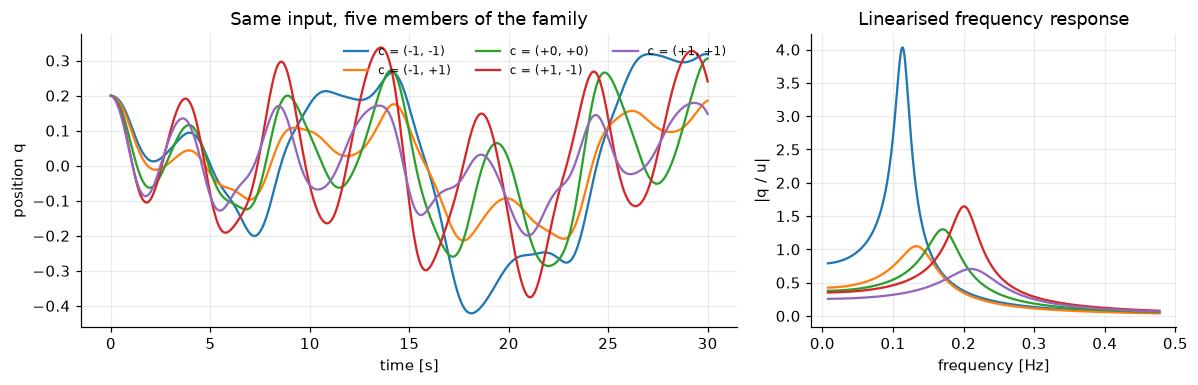

In [3]:
systems = [sample_system(rng, c) for c in [(-1, -1), (-1, 1), (0, 0), (1, -1), (1, 1)]]
u_demo = multisine(300, rng, n=5)
t = DT * np.arange(301)
omega = np.linspace(0.05, 3, 400)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[1.8, 1]))
for s in systems:
    q, _ = simulate(s, u_demo, rng, noise=False)
    ax1.plot(t, q, lw=1.5, label=f"c = ({s['context'][0]:+.0f}, {s['context'][1]:+.0f})")
    k, d, b, _ = s["eta"]
    ax2.plot(omega / (2 * np.pi), 0.5 * b / np.abs(k - omega**2 + 1j * d * omega), lw=1.5)
ax1.set(xlabel="time [s]", ylabel="position q", title="Same input, five members of the family")
ax1.legend(ncol=3, fontsize=8, loc="upper right")
ax2.set(xlabel="frequency [Hz]", ylabel="|q / u|", title="Linearised frequency response")
plt.tight_layout(); plt.show()

The same input produces clearly different motions. The frequency responses show why: the members
differ in resonance frequency (roughly 0.1–0.25 Hz, i.e. a period of 4–10 s), in how peaked
the resonance is, and in gain. A model of the *average* system will therefore mispredict most
individual systems. Keep the resonance band in mind; it returns in §7.

## 2. What the learner sees, and what it does not

In the laboratory, the learner can **choose the input** $u_t$ and **read a position sensor**
$y_t = q_t + \nu_t$. It does *not* see the velocity, the disturbance, or the coefficients.

| Quantity | Simulator knows | Learner receives |
|---|:---:|:---:|
| coefficients $\eta$, hidden context $c$ | ✔ | ✘ |
| input $u_t$ | ✔ | ✔ (it chooses it) |
| position $q_t$ | ✔ | only noisy $y_t$ |
| velocity $v_t$, disturbance $w_t$ | ✔ | ✘ |
| quintic term, bias | ✔ | ✘ (not even in its model) |

The learner's model is the equation of §1 **without** the unknown extra effects:

$$
\hat v_{t+1} = \hat v_t + \Delta t\,\big(-k\hat q_t - d\hat v_t + b\,\varphi(u_{t-1}) - \alpha \hat q_t^3\big),
\qquad \hat q_{t+1} = \hat q_t + \Delta t\,\hat v_{t+1}.
$$

This mismatch is deliberate. Real models are always wrong in some way, and a method is only
interesting if it degrades gracefully when that happens.

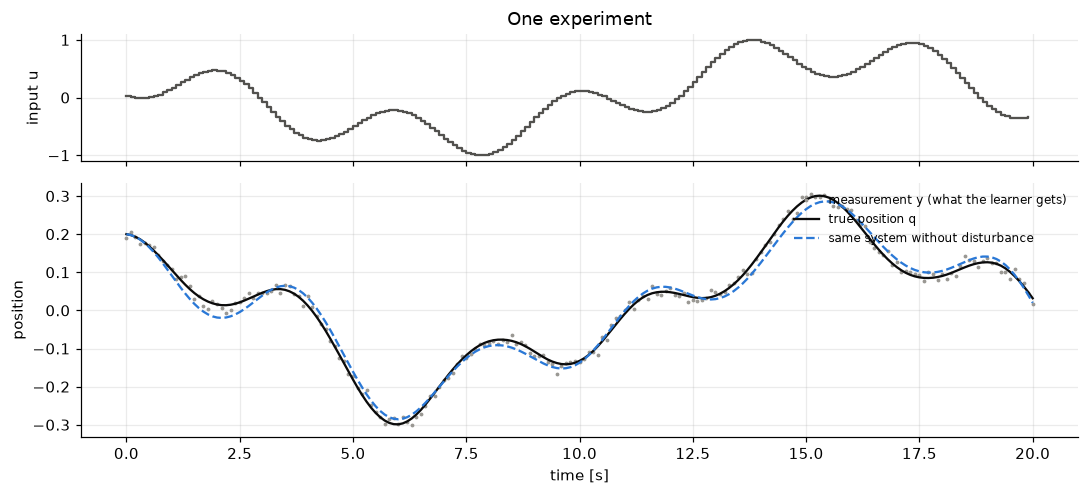

In [4]:
s = systems[2]
u = multisine(200, rng)
q_true, y = simulate(s, u, rng)
q_clean, _ = simulate(s, u, rng, noise=False)
t = DT * np.arange(201)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True, gridspec_kw=dict(height_ratios=[1, 2]))
ax1.step(t[:-1], u, where="post", color=COLOR["reference"], lw=1.5)
ax1.set(ylabel="input u", title="One experiment")
ax2.plot(t, y, ".", ms=3, color=COLOR["measured"], label="measurement y (what the learner gets)")
ax2.plot(t, q_true, color=COLOR["truth"], lw=1.5, label="true position q")
ax2.plot(t, q_clean, "--", color=COLOR["context"], lw=1.5, label="same system without disturbance")
ax2.set(xlabel="time [s]", ylabel="position"); ax2.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

The gap between the solid and the dashed line is caused by the coloured disturbance alone. No model
can predict it in advance, so we will judge models by how well they predict the system's
**disturbance-free response** to a new input: this measures the quality of the *model*, not our luck
with the noise.

## 3. Baseline: identifying one system from scratch

The classical approach treats every system on its own. Given one experiment $(u_{0:T-1}, y_{0:T})$,
**output-error identification** chooses the coefficients whose simulated position best matches the
measurements:

$$
\hat\eta = \arg\min_{\eta}\ \sum_{t=0}^{T} \big(y_t - \hat q_t(\eta; u)\big)^2 .
$$

We simulate the model *freely* from the known initial state rather than fitting one-step-ahead
differences. This avoids differentiating the noisy position to recover velocity.
The optimisation is started from a generic guess with physically sensible bounds.

In [5]:
LOW = np.array([0.05, 0.01, 0.05, 0.0])
HIGH = np.array([5.0, 2.0, 3.0, 5.0])
GENERIC_GUESS = np.array([1.0, 0.5, 1.0, 0.5])


def predict(eta, u):
    # Learner's model: simulate positions. Vectorised: eta (..., 4) and u (..., T) broadcast.
    eta, u = np.asarray(eta, float), np.asarray(u, float)
    shape = np.broadcast_shapes(eta.shape[:-1], u.shape[:-1])
    k, d, b, a = (np.broadcast_to(eta[..., i], shape) for i in range(4))
    force = actuator(np.concatenate([np.zeros(u.shape[:-1] + (1,)), u[..., :-1]], axis=-1))
    q, v = np.full(shape, X0[0]), np.full(shape, X0[1])
    out = np.empty(shape + (u.shape[-1] + 1,)); out[..., 0] = q
    for t in range(u.shape[-1]):
        v = v + DT * (-k * q - d * v + b * force[..., t] - a * q**3)
        q = q + DT * v
        out[..., t + 1] = q
    return out


def fit_from_scratch(y, u, return_cov=False):
    residual = lambda eta: predict(eta, u) - y
    sol = least_squares(residual, GENERIC_GUESS, bounds=(LOW, HIGH), x_scale="jac")
    if not return_cov:
        return sol.x
    # Gauss-Newton covariance of the estimate: sigma^2 (J^T J)^-1
    return sol.x, np.mean(sol.fun**2) * np.linalg.pinv(sol.jac.T @ sol.jac)


def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

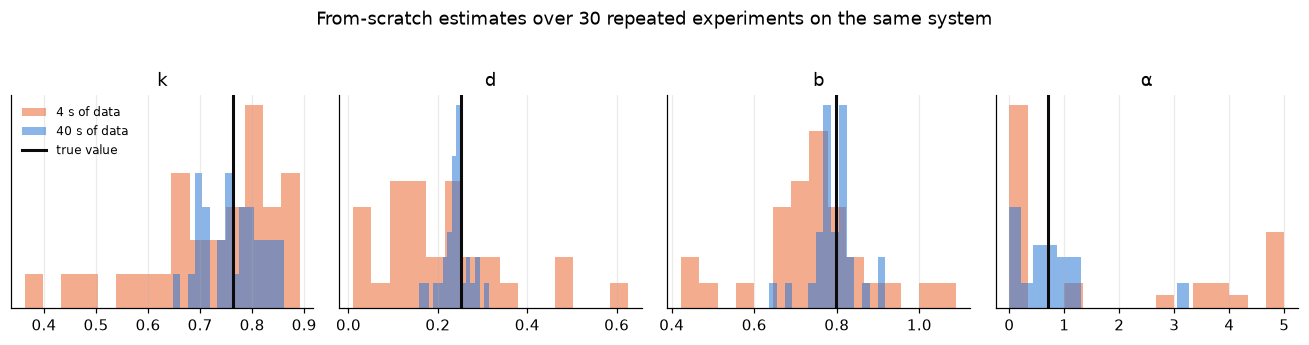

   4 s  median relative error: k= 10.4%  d= 37.3%  b=  9.8%  α=100.0%
  40 s  median relative error: k=  6.4%  d=  6.2%  b=  2.7%  α= 46.9%


In [6]:
test = sample_system(rng)
estimates = {}
for T in (40, 400):                                      # 4 s versus 40 s of data
    estimates[T] = np.array([fit_from_scratch(simulate(test, u, rng)[1], u)
                             for u in (multisine(T, rng) for _ in range(30))])

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for j, ax in enumerate(axes):
    for T, col in ((40, COLOR["scratch"]), (400, COLOR["context"])):
        ax.hist(estimates[T][:, j], bins=15, alpha=0.55, color=col, label=f"{T*DT:.0f} s of data")
    ax.axvline(test["eta"][j], color=COLOR["truth"], lw=2, label="true value")
    ax.set(title=NAMES[j], yticks=[])
axes[0].legend(fontsize=8)
fig.suptitle("From-scratch estimates over 30 repeated experiments on the same system", y=1.03)
plt.tight_layout(); plt.show()

for T in (40, 400):
    rel = np.median(np.abs(estimates[T] - test["eta"]) / test["eta"], axis=0)
    print(f"{T*DT:>4.0f} s  median relative error:", "  ".join(f"{n}={100*r:5.1f}%" for n, r in zip(NAMES, rel)))

Two lessons:

1. **Short experiments leave the coefficients poorly determined.** Four seconds is shorter than one
   oscillation period, so many coefficient combinations explain the data equally well. The estimates
   scatter widely.
2. **Some coefficients are hard to identify even with plenty of data.** The hardening term $\alpha$
   only matters at large deflections, and it competes with the unmodelled quintic term and the
   disturbance. With 40 s, $k$, $d$ and $b$ are within a few percent, but $\alpha$ is still uncertain
   by tens of percent. Identifiability depends on the *experiment* as much as on its length.

A new system gives us little data. The obvious question: can other systems help?

## 4. Pretraining: learning what systems of this kind have in common

Suppose we have long historical recordings (80 s each) of 20 other systems from the same family, e.g. from
end-of-line tests. **Pretraining** has two steps.

**Step 1: identify each training system.** With 80 s of data each, we obtain estimates
$\hat\eta_1,\dots,\hat\eta_{20}$ *and* their uncertainties: the Gauss–Newton covariance
$\hat\sigma_i^2(J_i^\top J_i)^{-1}$ of each fit.

**Step 2: learn the geometry of the family.** We look for a low-dimensional description of how the
coefficients vary from system to system. Principal component analysis (PCA) finds the best
rank-$r$ affine approximation

$$
\hat\eta_i \approx \bar\eta + U z_i, \qquad z_i \in \mathbb R^r, \quad z_i \sim \mathcal N(0, I),
$$

where $\bar\eta$ is the average system and the columns of $U$ are the main directions of variation,
scaled so that the *task context* $z$ has unit variance across the family. $\bar\eta$ and $U$ are the
"pretrained backbone"; $z$ is the small part that changes from system to system. We also record the
typical size of the output residual $\hat\sigma$: the noise level the model should expect.

**A trap, and its fix.** Plain PCA looks for the directions of largest *spread* in the estimates.
But $\hat\eta_i$ spreads for two reasons: genuine differences between systems, and estimation
error. §3 showed that $\alpha$ is poorly identified, so its estimates scatter widely, and plain PCA
would spend a principal direction on this *noise*. The remedy is to measure every coefficient in
units of its own estimation uncertainty before running PCA (**noise-whitened PCA**, a simple form of
factor analysis): with $s_j$ the average estimation standard deviation of coefficient $j$,
PCA is applied to $(\hat\eta_{ij}-\bar\eta_j)/s_j$, and $U$ is mapped back to physical units.
Directions are then ranked by *signal-to-noise ratio* rather than raw spread.

In [7]:
class Family:
    # Pretrained low-dimensional model of a family of systems.

    def fit(self, fits, data, rank=2, whiten=True):
        # fits: list of (eta_hat, covariance) from fit_from_scratch(..., return_cov=True)
        self.eta_hat = np.array([eta for eta, _ in fits])
        self.sigma = np.sqrt(np.mean([np.mean((predict(e, u) - y) ** 2)
                                      for e, (y, u) in zip(self.eta_hat, data)]))
        self.mean = self.eta_hat.mean(axis=0)
        self.scale = (np.sqrt(np.mean([np.diag(cov) for _, cov in fits], axis=0))
                      if whiten else np.ones(4))
        centred = (self.eta_hat - self.mean) / self.scale
        _, sv, vt = np.linalg.svd(centred, full_matrices=False)
        var = sv**2 / (len(centred) - 1)
        self.explained = var / var.sum()
        self.U = self.scale[:, None] * vt[:rank].T * np.sqrt(var[:rank])
        self.z_train = centred @ vt[:rank].T / np.sqrt(var[:rank])
        return self

    def decode(self, z):
        return np.clip(self.mean + np.asarray(z) @ self.U.T, LOW, HIGH)

    def project(self, eta):
        # Best context for known coefficients, in the whitened metric (used only for evaluation).
        return np.linalg.lstsq(self.U / self.scale[:, None], (eta - self.mean) / self.scale, rcond=None)[0]


def r_squared(Z, C):
    # Share of the variance of the hidden variables C explained by an affine function of Z.
    A = np.c_[Z, np.ones(len(Z))]
    residual = C - A @ np.linalg.lstsq(A, C, rcond=None)[0]
    return 1 - (residual**2).sum(axis=0) / ((C - C.mean(axis=0)) ** 2).sum(axis=0)


train_systems = [sample_system(rng) for _ in range(20)]
train_data = []
for s in train_systems:
    u = multisine(800, rng, n=6)
    train_data.append((simulate(s, u, rng)[1], u))
train_fits = [fit_from_scratch(y, u, return_cov=True) for y, u in train_data]
family = Family().fit(train_fits, train_data)
naive = Family().fit(train_fits, train_data, whiten=False)
true_train = np.array([s["eta"] for s in train_systems])
hidden = np.array([s["context"] for s in train_systems])

print("Estimation std per coefficient (k, d, b, α):", np.round(family.scale, 4))
print("Variance explained by each principal direction:", np.round(family.explained, 3))
print(f"Estimated residual noise level sigma = {family.sigma:.4f}  (sensor noise alone: {_SIGMA_Y})")
print()
print("How well do the learned contexts explain the hidden design variables (R², 1 = perfectly)?")
for name, fam in (("plain PCA", naive), ("noise-whitened PCA", family)):
    r2 = r_squared(fam.z_train, hidden)
    print(f"  {name:>18s}:  c1 {r2[0]:.2f}   c2 {r2[1]:.2f}")

Estimation std per coefficient (k, d, b, α): [0.0111 0.0054 0.0069 0.3616]
Variance explained by each principal direction: [0.784 0.194 0.019 0.003]
Estimated residual noise level sigma = 0.0184  (sensor noise alone: 0.01)

How well do the learned contexts explain the hidden design variables (R², 1 = perfectly)?
           plain PCA:  c1 0.96   c2 0.35
  noise-whitened PCA:  c1 0.98   c2 0.96


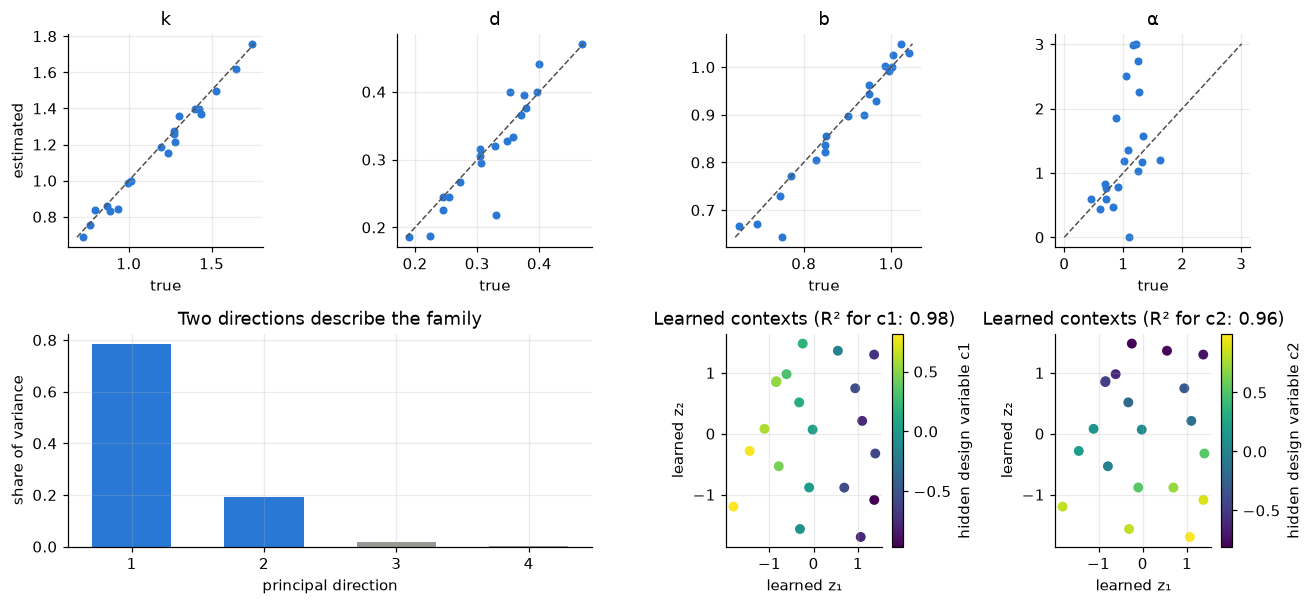

In [8]:
fig = plt.figure(figsize=(12, 5.6))
grid = fig.add_gridspec(2, 4)
for j in range(4):
    ax = fig.add_subplot(grid[0, j])
    ax.scatter(true_train[:, j], family.eta_hat[:, j], s=18, color=COLOR["context"])
    lim = [min(true_train[:, j].min(), family.eta_hat[:, j].min()),
           max(true_train[:, j].max(), family.eta_hat[:, j].max())]
    ax.plot(lim, lim, "--", color=COLOR["reference"], lw=1)
    ax.set(title=NAMES[j], xlabel="true", ylabel="estimated" if j == 0 else None)
ax = fig.add_subplot(grid[1, :2])
ax.bar(np.arange(1, 5), family.explained, color=[COLOR["context"]] * 2 + [COLOR["none"]] * 2, width=0.6)
ax.set(xticks=range(1, 5), xlabel="principal direction", ylabel="share of variance",
       title="Two directions describe the family")
r2 = r_squared(family.z_train, hidden)
for j in range(2):
    ax = fig.add_subplot(grid[1, 2 + j])
    sc = ax.scatter(*family.z_train.T, c=hidden[:, j], cmap="viridis", s=30)
    fig.colorbar(sc, ax=ax, label=f"hidden design variable c{j+1}")
    ax.set(xlabel="learned z₁", ylabel="learned z₂", title=f"Learned contexts (R² for c{j+1}: {r2[j]:.2f})")
plt.tight_layout(); plt.show()

- **Top row.** Stiffness, damping and gain are identified well from long recordings; $\alpha$ is only
  roughly determined (as §3 predicted). Pretraining inherits these imperfections.
- **Bottom left.** Two directions explain almost all of the (noise-weighted) variation. The learner
  has discovered, from data alone, that the family is essentially two-dimensional.
- **Bottom right.** The learned coordinates $z$ encode both hidden design variables smoothly. They are
  a rotated and rescaled version of $c$: PCA cannot know the "names" of the hidden variables, and
  it does not need to.
- **The printout above** shows why the noise weighting matters. Plain PCA recovers the first design
  variable but largely misses the second, because it spends a direction on the scatter of the
  poorly identified $\alpha$. *What a model can learn from a population is limited by what can be
  identified in each of its members.*

This is the miniature version of a foundation model. A large model would replace the fixed physics
equation by a neural state-space model and PCA by a learned encoder. The division of labour stays
the same: **a shared backbone plus a small system-specific context.**

## 5. Few-shot adaptation: identify two numbers instead of four

For a new system we freeze $\bar\eta$ and $U$ and estimate only the context $z$. The pretraining
distribution $z\sim\mathcal N(0,I)$ is a natural prior, which gives the maximum-a-posteriori estimate

$$
\hat z = \arg\min_z \ \frac{1}{\hat\sigma^2}\sum_t \big(y_t - \hat q_t(\bar\eta + Uz;\,u)\big)^2 + \|z\|^2 .
$$

The Laplace approximation also gives an uncertainty. With $S = \partial \hat q/\partial z$ the output
sensitivity at $\hat z$,

$$
\operatorname{Cov}(z \mid \text{data}) \approx \big(\hat\sigma^{-2} S^\top S + I\big)^{-1}.
$$

Two things improve at once: there are fewer unknowns, and the prior keeps them in the region where
systems of this kind actually live.

In [9]:
def adapt(family, y, u):
    # MAP estimate of the context, its Laplace covariance, and the RMS output misfit.
    residual = lambda z: np.r_[(predict(family.decode(z), u) - y) / family.sigma, z]
    sol = least_squares(residual, np.zeros(family.U.shape[1]))
    S = sol.jac[:-len(sol.x)] * family.sigma
    cov = np.linalg.inv(S.T @ S / family.sigma**2 + np.eye(len(sol.x)))
    misfit = rmse(predict(family.decode(sol.x), u), y)
    return sol.x, cov, misfit


def ellipse(ax, mean, cov, color, label=None, n_std=2.0):
    vals, vecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(vecs[1, -1], vecs[0, -1]))
    ax.add_patch(Ellipse(mean, *(2 * n_std * np.sqrt(vals[::-1])), angle=angle,
                         fill=False, color=color, lw=2, label=label))

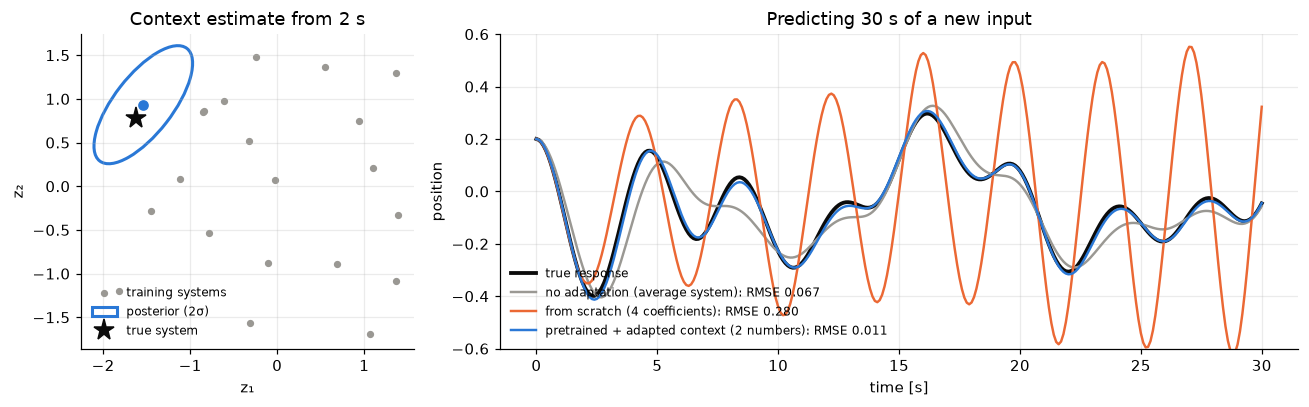

In [10]:
new = sample_system(rng)
u_short = multisine(20, rng)                           # 2 seconds of data
_, y_short = simulate(new, u_short, rng)
z_hat, z_cov, _ = adapt(family, y_short, u_short)
eta_scratch = fit_from_scratch(y_short, u_short)

u_val = multisine(300, rng, n=6)                       # a new input the model has never seen
q_val, _ = simulate(new, u_val, rng, noise=False)
models = {"no adaptation (average system)": (family.mean, COLOR["none"]),
          "from scratch (4 coefficients)": (eta_scratch, COLOR["scratch"]),
          "pretrained + adapted context (2 numbers)": (family.decode(z_hat), COLOR["context"])}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1, 2.4]))
ax1.scatter(*family.z_train.T, s=14, color=COLOR["none"], label="training systems")
ellipse(ax1, z_hat, z_cov, COLOR["context"], "posterior (2σ)")
ax1.plot(*z_hat, "o", color=COLOR["context"])
ax1.plot(*family.project(new["eta"]), "*", ms=14, color=COLOR["truth"], label="true system")
ax1.set(xlabel="z₁", ylabel="z₂", title="Context estimate from 2 s"); ax1.legend(fontsize=8)
tv = DT * np.arange(301)
example_rmse = {name: rmse(predict(eta, u_val), q_val) for name, (eta, _) in models.items()}
ax2.plot(tv, q_val, color=COLOR["truth"], lw=2.5, label="true response")
for name, (eta, col) in models.items():
    ax2.plot(tv, predict(eta, u_val), color=col, lw=1.6, label=f"{name}: RMSE {example_rmse[name]:.3f}")
ax2.set(xlabel="time [s]", ylabel="position", ylim=(-0.6, 0.6), title="Predicting 30 s of a new input")
ax2.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

With only two seconds of data (a third of an oscillation period), fitting four coefficients from
scratch overfits badly. It explains the short experiment, but the coefficients it finds describe a
different, barely damped oscillator, and its predictions drift far from reality. Adapting two
pretrained context values gives a model that predicts 30 seconds of unseen behaviour well. The
posterior ellipse shows how certain the estimate is, and it contains the true system.

One example proves little, so we now evaluate systematically.

## 6. When is pretraining worth it? A data-budget study

For each experiment length we draw **40 new systems**, run one random experiment on each, and compare:

- **no adaptation**: always predict with the average system $\bar\eta$;
- **from scratch**: fit all four coefficients (§3);
- **pretrained + context**: adapt $z$ (§5), using *the same* data;
- **reference**: the true coefficients $\eta$ plugged into the learner's model. This is not zero
  error, because the model lacks the quintic term and the bias.

Error is the RMSE of the predicted disturbance-free response to a fresh 30 s input.

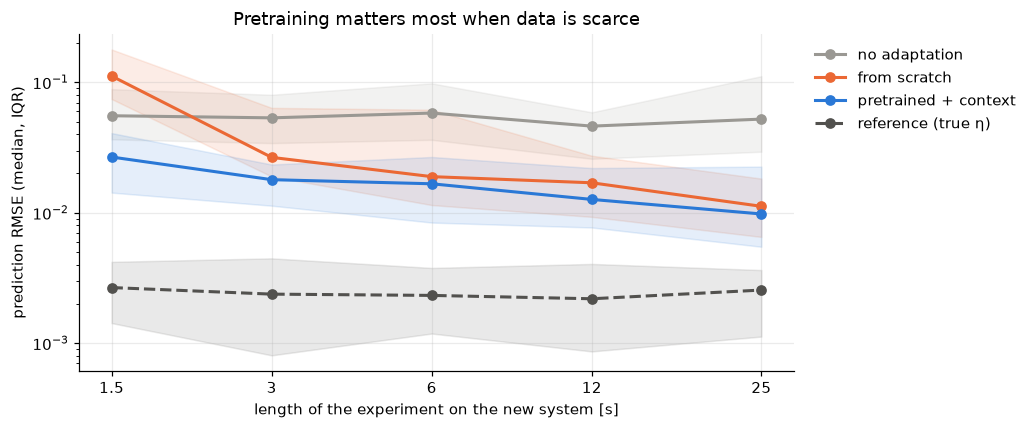

  1.5 s: from-scratch error is  4.2x the pretrained error
  3.0 s: from-scratch error is  1.5x the pretrained error
  6.0 s: from-scratch error is  1.1x the pretrained error
 12.0 s: from-scratch error is  1.3x the pretrained error
 25.0 s: from-scratch error is  1.1x the pretrained error


In [11]:
budgets = [15, 30, 60, 120, 250]                        # samples; x 0.1 s
methods = ["none", "scratch", "context", "reference"]
budget_err = {m: np.zeros((len(budgets), 40)) for m in methods}
for i, T in enumerate(budgets):
    for n in range(40):
        s = sample_system(rng); u = multisine(T, rng); _, y = simulate(s, u, rng)
        u_val = multisine(300, rng, n=6); q_val, _ = simulate(s, u_val, rng, noise=False)
        etas = dict(none=family.mean, scratch=fit_from_scratch(y, u),
                    context=family.decode(adapt(family, y, u)[0]), reference=s["eta"])
        for m in methods:
            budget_err[m][i, n] = rmse(predict(etas[m], u_val), q_val)

labels = dict(none="no adaptation", scratch="from scratch", context="pretrained + context",
              reference="reference (true η)")
seconds = DT * np.array(budgets)
fig, ax = plt.subplots(figsize=(9.5, 4))
for m in methods:
    med = np.median(budget_err[m], axis=1)
    lo, hi = np.percentile(budget_err[m], [25, 75], axis=1)
    ls = "--" if m == "reference" else "-"
    ax.plot(seconds, med, ls, marker="o", color=COLOR[m], label=labels[m])
    ax.fill_between(seconds, lo, hi, color=COLOR[m], alpha=0.12)
ax.set(xscale="log", yscale="log", xlabel="length of the experiment on the new system [s]",
       ylabel="prediction RMSE (median, IQR)", xticks=seconds, xticklabels=[f"{x:g}" for x in seconds],
       title="Pretraining matters most when data is scarce")
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

for i, T in enumerate(budgets):
    ratio = np.median(budget_err["scratch"][i]) / np.median(budget_err["context"][i])
    print(f"{T*DT:5.1f} s: from-scratch error is {ratio:4.1f}x the pretrained error")

The pattern is the central message of few-shot learning:

- **Scarce data (a few seconds):** from scratch is worse than doing nothing, because it overfits.
  The pretrained model is already useful.
- **More data:** from scratch improves steadily and the gap narrows. Pretraining buys data
  efficiency, not a better final model.
- **All learned models stay above the reference.** The remaining error comes from the imperfect
  pretraining (e.g. the poorly identified $\alpha$) and the rank-2 restriction. Neither can be
  fixed by collecting more data on the new system; only a better model class can.

So far every experiment was random. Can we do better by *choosing* the experiment?

## 7. Designing an informative experiment

An experiment is informative if systems with different contexts respond *differently* to it. If
a small change in $z$ barely changes the output, the data cannot tell the contexts apart. This is
quantified by the **Fisher information** of the context,

$$
\mathcal I(u; z) = \hat\sigma^{-2}\, S(u;z)^\top S(u;z) + I, \qquad S_{tj} = \frac{\partial \hat q_t}{\partial z_j},
$$

whose inverse is the posterior covariance of §5. We do not know the new system's $z$ yet, so we
average over plausible systems (the training contexts) and maximise the expected log-determinant
(**Bayesian D-optimal design**). This minimises the expected volume of the posterior ellipse:

$$
u^\star = \arg\max_{u \in \mathcal U} \ \frac{1}{|Z|}\sum_{z \in Z} \log\det \mathcal I(u; z).
$$

In practice we score many admissible random inputs and pick the best. All of this is computed
*before* touching the new system, using only the pretrained model.

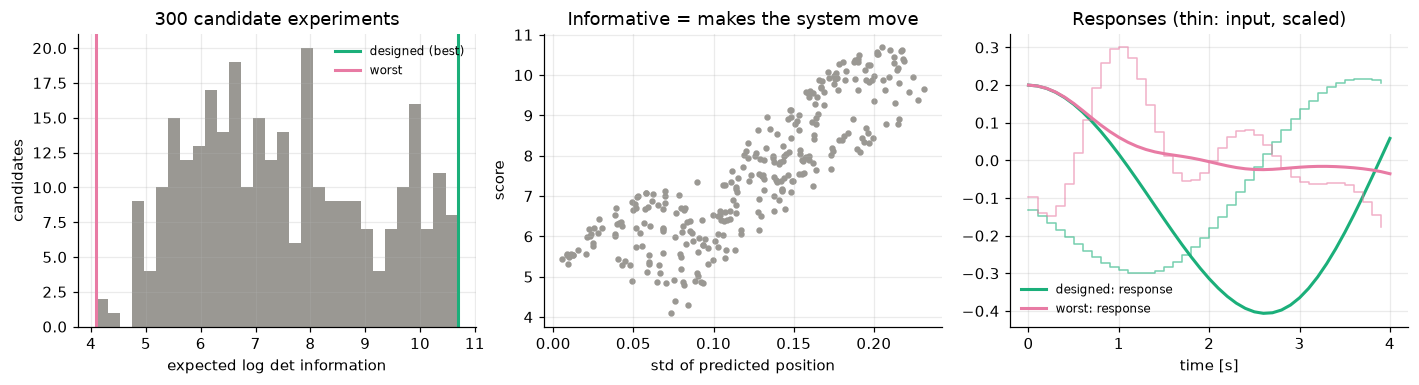

correlation(score, motion) = 0.85


In [12]:
def fisher(family, U_in, Z, eps=1e-4):
    # Fisher information for inputs U_in (N, T) at contexts Z (M, 2) -> array (N, M, 2, 2).
    U_in = np.asarray(U_in)[:, None, :]
    S = np.stack([(predict(family.decode(Z + eps * e)[None], U_in)
                   - predict(family.decode(Z - eps * e)[None], U_in)) / (2 * eps)
                  for e in np.eye(2)], axis=-1)
    return np.einsum("nmti,nmtj->nmij", S, S) / family.sigma**2 + np.eye(2)


def design_score(family, U_in):
    return np.linalg.slogdet(fisher(family, U_in, family.z_train))[1].mean(axis=1)


T = 40
candidates = np.array([multisine(T, rng) for _ in range(300)])
scores = design_score(family, candidates)
best, worst = candidates[np.argmax(scores)], candidates[np.argmin(scores)]
motion = predict(family.mean, candidates).std(axis=1)          # how much the average system moves

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(scores, bins=30, color=COLOR["none"])
axes[0].axvline(scores.max(), color=COLOR["designed"], lw=2, label="designed (best)")
axes[0].axvline(scores.min(), color=COLOR["worst"], lw=2, label="worst")
axes[0].set(xlabel="expected log det information", ylabel="candidates", title="300 candidate experiments")
axes[0].legend(fontsize=8)
axes[1].scatter(motion, scores, s=10, color=COLOR["none"])
axes[1].set(xlabel="std of predicted position", ylabel="score", title="Informative = makes the system move")
tt = DT * np.arange(T + 1)
for u_, col, lab in ((best, COLOR["designed"], "designed"), (worst, COLOR["worst"], "worst")):
    axes[2].plot(tt, predict(family.mean, u_), color=col, label=f"{lab}: response")
    axes[2].step(tt[:-1], 0.3 * u_, where="post", color=col, lw=1, alpha=0.6)
axes[2].set(xlabel="time [s]", title="Responses (thin: input, scaled)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"correlation(score, motion) = {np.corrcoef(motion, scores)[0, 1]:.2f}")

The physics is visible. The best experiments push slowly enough to swing the cart through
large, two-sided motions near the resonance band from §1. The worst ones shake it at high
frequency, which the mass filters out, so the sensor sees mostly noise. The score is not just
"more motion" though: *how* the system moves decides which coefficient combinations become
distinguishable.

The same new system, identified with three different 4-second experiments:

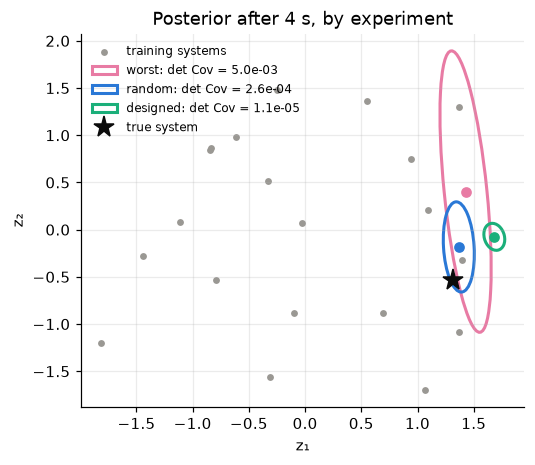

In [13]:
new = sample_system(rng)
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.scatter(*family.z_train.T, s=12, color=COLOR["none"], label="training systems")
posterior_det = {}
for u_, col, lab in ((worst, COLOR["worst"], "worst"), (multisine(T, rng), COLOR["context"], "random"),
                     (best, COLOR["designed"], "designed")):
    z_, cov_, _ = adapt(family, simulate(new, u_, rng)[1], u_)
    posterior_det[lab] = np.linalg.det(cov_)
    ellipse(ax, z_, cov_, col, f"{lab}: det Cov = {posterior_det[lab]:.1e}")
    ax.plot(*z_, "o", color=col)
ax.plot(*family.project(new["eta"]), "*", ms=14, color=COLOR["truth"], label="true system")
ax.set(xlabel="z₁", ylabel="z₂", title="Posterior after 4 s, by experiment"); ax.legend(fontsize=8)
plt.show()

The designed experiment shrinks the uncertainty region by orders of magnitude. But look closely: the
smallest ellipse does not contain the true system. The Laplace posterior is **overconfident**,
because it assumes white noise and a perfect model, while the real disturbance is coloured and the
model lacks the quintic term. A small ellipse is a promise, not a guarantee.

Does the promise deliver better *predictions* on new systems? We repeat the comparison over
**60 new systems per budget**. In every trial a fresh pool of 200 candidates is
scored, the designed and the worst experiment are picked, and a random experiment is drawn
**without looking at its score**.

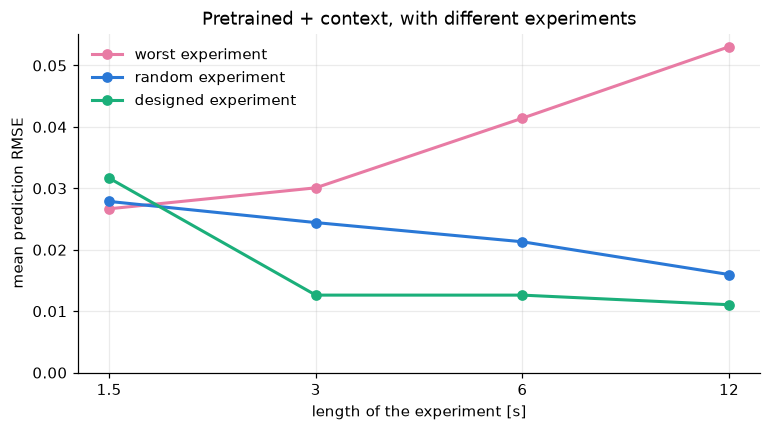

 length | random  designed | reduction | designed wins | 95% CI of mean reduction
  1.5 s | 0.0279  0.0317 |  -13.6 %  |      48 %     | [-0.0096, +0.0013]
  3.0 s | 0.0244  0.0126 |   48.3 %  |      73 %     | [+0.0076, +0.0164]
  6.0 s | 0.0213  0.0126 |   40.8 %  |      78 %     | [+0.0059, +0.0118]
 12.0 s | 0.0160  0.0111 |   30.8 %  |      73 %     | [+0.0018, +0.0086]


In [14]:
design_budgets = [15, 30, 60, 120]
design_err = {m: np.zeros((len(design_budgets), 60)) for m in ("worst", "context", "designed")}
for i, T in enumerate(design_budgets):
    for n in range(60):
        pool = np.array([multisine(T, rng) for _ in range(200)])
        sc = design_score(family, pool)
        inputs = dict(worst=pool[np.argmin(sc)], context=multisine(T, rng), designed=pool[np.argmax(sc)])
        s = sample_system(rng)
        u_val = multisine(300, rng, n=6); q_val, _ = simulate(s, u_val, rng, noise=False)
        for m, u_ in inputs.items():
            z_, _, _ = adapt(family, simulate(s, u_, rng)[1], u_)
            design_err[m][i, n] = rmse(predict(family.decode(z_), u_val), q_val)

seconds = DT * np.array(design_budgets)
fig, ax = plt.subplots(figsize=(8, 4))
for m, lab in (("worst", "worst experiment"), ("context", "random experiment"), ("designed", "designed experiment")):
    ax.plot(seconds, design_err[m].mean(axis=1), marker="o", color=COLOR[m], label=lab)
ax.set(xscale="log", xticks=seconds, xticklabels=[f"{x:g}" for x in seconds], ylim=(0, None),
       xlabel="length of the experiment [s]", ylabel="mean prediction RMSE",
       title="Pretrained + context, with different experiments")
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.legend(); plt.show()

print(" length | random  designed | reduction | designed wins | 95% CI of mean reduction")
design_stats = []
for i, T in enumerate(design_budgets):
    diff = design_err["context"][i] - design_err["designed"][i]
    boot = diff[rng.integers(0, diff.size, (5000, diff.size))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    design_stats.append(dict(reduction=diff.mean() / design_err["context"][i].mean(),
                             win=np.mean(diff > 0), ci=[lo, hi]))
    print(f"{T*DT:5.1f} s | {design_err['context'][i].mean():.4f}  {design_err['designed'][i].mean():.4f} |"
          f"  {100*diff.mean()/design_err['context'][i].mean():5.1f} %  |     {100*np.mean(diff > 0):3.0f} %     |"
          f" [{lo:+.4f}, {hi:+.4f}]")

Read the table as a function of the budget:

- **Very short (1.5 s):** no experiment can reveal much in a quarter of an oscillation period. The
  difference between designed and random is not significant (the interval contains zero); the
  prior does most of the work.
- **3 s and more:** design pays off. The designed experiment lowers the error by roughly a third to
  a half, wins about three out of four paired trials, and its confidence interval excludes zero.
  The worst experiments waste most of the data.
- **Growing budgets:** the relative advantage is largest for the shortest informative experiments
  and shrinks as the experiment gets longer, because random experiments then also contain enough
  information.

The comparison is fair by construction: the random input is never scored, and the designed input
is chosen before the new system is touched. Even so, the designed experiment does not win every
single trial. Noise and model mismatch remain, and the criterion targets parameter uncertainty, not
the prediction error itself. Designing for *goal-oriented* criteria is a research topic of its own.

## 8. Knowing when the shared knowledge does not apply

The pretrained model is only as good as the family it has seen. What happens when a new system
varies in a way **never seen during pretraining**, e.g. a worn bearing changing damping and gain in
an unusual combination? We move the true coefficients a distance $\delta$ away from the learned
family, along a direction orthogonal to $U$, and adapt with 12 s of data. A two-number context
cannot represent the change.

The adaptation itself offers a warning signal: the **output misfit**. If the best context still
cannot explain the data, the residual is larger than it is for normal members of the family.
We calibrate a threshold as the 95th percentile of the misfit on in-family systems.

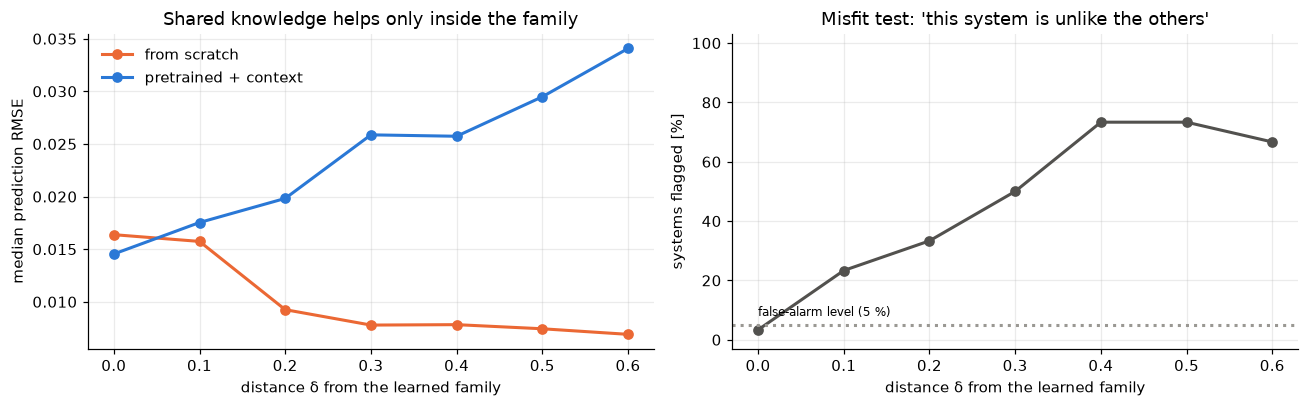

direction of change in [k, d, b, α]: [-0.16  0.97 -0.13 -0.15]


In [15]:
T = 120
basis_out = np.linalg.svd(family.U, full_matrices=True)[0][:, 2:]   # directions the context cannot express
direction = basis_out[:, np.argmax(np.abs(basis_out[1]))]          # the one that moves damping most
direction *= np.sign(direction[1]) / np.linalg.norm(direction)

in_family = []
for _ in range(60):
    s = sample_system(rng); u = multisine(T, rng)
    in_family.append(adapt(family, simulate(s, u, rng)[1], u)[2])
threshold = np.quantile(in_family, 0.95)

shifts = np.linspace(0, 0.6, 7)
shift_err = {m: np.zeros((len(shifts), 30)) for m in ("scratch", "context")}
flagged = np.zeros((len(shifts), 30), bool)
for i, delta in enumerate(shifts):
    for n in range(30):
        s = sample_system(rng)
        s["eta"] = np.clip(s["eta"] + delta * direction, LOW + 0.02, HIGH)
        u = multisine(T, rng); _, y = simulate(s, u, rng)
        u_val = multisine(300, rng, n=6); q_val, _ = simulate(s, u_val, rng, noise=False)
        z_, _, misfit = adapt(family, y, u)
        shift_err["context"][i, n] = rmse(predict(family.decode(z_), u_val), q_val)
        shift_err["scratch"][i, n] = rmse(predict(fit_from_scratch(y, u), u_val), q_val)
        flagged[i, n] = misfit > threshold

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
for m, lab in (("scratch", "from scratch"), ("context", "pretrained + context")):
    ax1.plot(shifts, np.median(shift_err[m], axis=1), marker="o", color=COLOR[m], label=lab)
ax1.set(xlabel="distance δ from the learned family", ylabel="median prediction RMSE",
        title="Shared knowledge helps only inside the family"); ax1.legend()
ax2.plot(shifts, 100 * flagged.mean(axis=1), marker="o", color=COLOR["reference"])
ax2.axhline(5, ls=":", color=COLOR["none"]); ax2.text(0.0, 8, "false-alarm level (5 %)", fontsize=8)
ax2.set(xlabel="distance δ from the learned family", ylabel="systems flagged [%]", ylim=(-3, 103),
        title="Misfit test: 'this system is unlike the others'")
plt.tight_layout(); plt.show()
print("direction of change in [k, d, b, α]:", np.round(direction, 2))

As the new system leaves the family, the pretrained model gets steadily worse, while the
from-scratch estimate is unaffected: it assumes nothing about the family. (Its error even
decreases, since more strongly damped systems move less and are easier to predict.) With 12 s of data, from scratch is already
competitive inside the family, so the pretrained model loses its advantage after a small shift.

The misfit test responds as it should. It flags about 5 % of normal systems, as designed, and its
detection rate rises with the shift to roughly three quarters of the systems. But **detection
lags degradation**: at moderate shifts the adapter is already worse than from scratch, while most
systems still pass the test, because the misfit is dominated by the disturbance.

This yields a simple decision rule: *use the small adapter while it explains the data, and fall back
to (or enlarge towards) full identification when it does not.* Making such a rule both sensitive
and trustworthy, with guarantees, is an open question for learned models.

## 9. Does a better model give better control?

Models are rarely the end goal; we want to *act*. As a simple model-based controller, we compute a
**feedforward input** that should move the cart along a reference trajectory $r_t$, by solving

$$
u^\star = \arg\min_{u}\ \sum_t \big(\hat q_t(\hat\eta; u) - r_t\big)^2 + \lambda\sum_t (u_{t+1}-u_t)^2
$$

with each candidate model, and then apply $u^\star$ to the **true** system. Feedforward cannot correct
errors while running, so it is a direct test of model quality. The context models use a designed
6-second experiment.

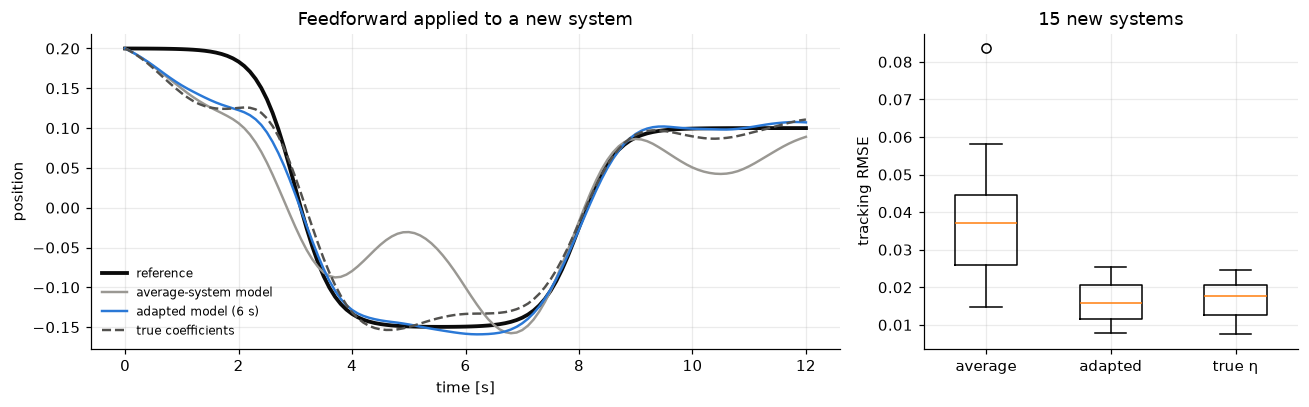

  average-system model: mean tracking RMSE = 0.0383
   adapted model (6 s): mean tracking RMSE = 0.0163
     true coefficients: mean tracking RMSE = 0.0170


In [16]:
T_ctrl = 120
tc = DT * np.arange(T_ctrl + 1)
ref = 0.2 - 0.35 * (1 / (1 + np.exp(-(tc - 3) * 3))) + 0.25 * (1 / (1 + np.exp(-(tc - 8) * 3)))


def feedforward(eta, lam=0.05, eps=1e-5):
    def residual(u):
        return np.r_[predict(eta, u) - ref, np.sqrt(lam) * np.diff(u)]
    def jacobian(u):                                       # vectorised finite differences
        batch = u + eps * np.vstack([np.zeros(T_ctrl), np.eye(T_ctrl)])
        r = np.c_[predict(eta, batch) - ref, np.sqrt(lam) * np.diff(batch, axis=1)]
        return ((r[1:] - r[0]) / eps).T
    return least_squares(residual, np.zeros(T_ctrl), jac=jacobian, bounds=(-2, 2)).x


pool = np.array([multisine(60, rng) for _ in range(200)])
u_design = pool[np.argmax(design_score(family, pool))]
ctrl_err = {m: [] for m in ("none", "context", "reference")}
ctrl_example = {}
for n in range(15):
    s = sample_system(rng)
    z_, _, _ = adapt(family, simulate(s, u_design, rng)[1], u_design)
    for m, eta in (("none", family.mean), ("context", family.decode(z_)), ("reference", s["eta"])):
        q_ctrl, _ = simulate(s, feedforward(eta), rng)
        ctrl_err[m].append(rmse(q_ctrl, ref))
        if n == 0:
            ctrl_example[m] = q_ctrl

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[2, 1]))
ax1.plot(tc, ref, color=COLOR["truth"], lw=2.5, label="reference")
lab = dict(none="average-system model", context="adapted model (6 s)", reference="true coefficients")
for m, q_ctrl in ctrl_example.items():
    ax1.plot(tc, q_ctrl, "--" if m == "reference" else "-", color=COLOR[m], lw=1.6, label=lab[m])
ax1.set(xlabel="time [s]", ylabel="position", title="Feedforward applied to a new system"); ax1.legend(fontsize=8)
ax2.boxplot([ctrl_err[m] for m in ctrl_err], tick_labels=["average", "adapted", "true η"], widths=0.5)
ax2.set(ylabel="tracking RMSE", title="15 new systems")
plt.tight_layout(); plt.show()
for m in ctrl_err:
    print(f"{lab[m]:>22s}: mean tracking RMSE = {np.mean(ctrl_err[m]):.4f}")

Six seconds of well-chosen data, interpreted through the pretrained family, cut the tracking error
by more than half compared with the average-system model, and match what the true coefficients
achieve. The adapted model can even be marginally better, because it is fitted to the real
behaviour and partly absorbs the unmodelled terms. The remaining error comes from the disturbance,
which only feedback can reject. A feedback controller would reduce all errors, but the ordering,
and the reason for it, would remain.

## 10. Summary and the road to a foundation model

| Step | In this notebook | At scale |
|---|---|---|
| Model class | known physics equation, 4 coefficients | structured neural state-space model / sequence model |
| Pretraining | per-system identification + noise-whitened PCA | joint training over many heterogeneous systems |
| Task context | 2 numbers $z$ with a Gaussian prior | learned context encoder, low-rank adapters, hypernetworks |
| Adaptation | MAP with Laplace uncertainty | amortised inference or fast gradient adaptation |
| Experiment design | D-optimal selection among candidates | safe, constrained, sequential (Bayesian) design |
| Reliability | misfit test against a calibrated threshold | calibrated uncertainty and out-of-distribution detection |
| Use | feedforward tracking | MPC, reinforcement learning, safe learning control |

**What we learned**

1. Knowledge of *similar* systems turns a four-parameter identification problem into a
   two-parameter one. This matters most exactly when data is scarce (§6).
2. The value of data depends on the experiment. An information criterion computed from the
   pretrained model chooses experiments that swing the system through its informative regime (§7).
3. Shared knowledge is a double-edged sword: outside the family it biases the answer. The same
   probabilistic machinery can detect this (§8).
4. Better models translate into better control (§9).

**Open questions this toy problem raises**

- *Identifiability:* when can the context of a learned (neural) backbone be recovered from partial,
  noisy measurements, and how much data does it need?
- *Calibration:* the Laplace posterior assumes white noise, while real disturbances are coloured.
  How do we obtain uncertainty we can trust for decision-making?
- *Safe excitation:* informative experiments push systems hard. How do we trade information
  against state and input constraints, ideally with guarantees?
- *Adapter capacity:* how do we decide online when a small context suffices and when the model
  must grow?
- *Closing the loop:* how should identification, uncertainty and control be designed jointly?